# <center>**M2 Bio-informatique - Projet MLB**<center>
Réalisé par Louis Debray et Benjamin Theuleau  
  
* <span style="color:lightgreen">Fini et validé</span>
* <span style="color:violet">Fini mais à valider</span>
* <span style="color:yellow">Point d'attention / à compléter</span>
* <span style="color:orange">En cours</span>
* <span style="color:red">Reste à faire</span>  
  
Pour plus d'information sur l'avancement du projet => README.md

# <span style="color:orange">Contexte de l’étude et objectifs</span>
<span style="color:red">**A FAIRE : J'ai juste copié/collé le texte du moodle. A remettre au propre et compléter avec ce qu'on voudra faire**</span>  
Les nuages constituent un défi majeur pour l’imagerie satellitaire passive, et la couverture nuageuse quotidienne ainsi que les averses dans le bassin amazonien peuvent compliquer considérablement la surveillance de la région. C’est pourquoi nous avons choisi d’inclure une mention relative à la couverture nuageuse pour chaque image. Ces mentions reflètent fidèlement ce que l’on verrait dans des prévisions météorologiques locales : ciel dégagé, partiellement nuageux, nuageux et brume. Dans le cadre de notre étude, la brume est définie comme toute image sur laquelle des nuages atmosphériques sont visibles, mais sans être suffisamment opaques pour masquer le sol.  
Les images « ciel dégagé » ne présentent aucun signe de nuages, tandis que les images « partiellement nuageux » peuvent montrer une couverture nuageuse opaque sur n’importe quelle partie de l’image. Les images « nuageux » présentent une couverture nuageuse opaque masquant 90 % de la zone d’imagerie. L’ensemble de données utilisé rassemble des images satellites de l’Amazonie et des étiquettes (« ciel dégagé », « partiellement nuageux », « nuageux » et « brume ») ; il peut être téléchargé depuis le site web de Kaggle ici. Cette présentation décrit une analyse de cet ensemble de données.

# <span style="color:orange">Organisation des répertoires</span>
|_ MLB/  
&emsp;|_ projet_MLB.ipynb  
&emsp;|_ images/  
&emsp;&emsp;|_ clear/  
&emsp;&emsp;|_ cloudy/  
&emsp;&emsp;|_ haze/  
&emsp;&emsp;|_ partly_cloudy/

# <span style="color:orange">Librairies</span>

In [2]:
import numpy as np
import os
import random
import rastereasy as re
import sklearn as skl

# <span style="color:orange">**I - Préparation des images**</span>

## <span style="color:orange">Description des images</span>
<span style="color:red">**A FAIRE : Décrire rapidement les 4 catégories d'images (dimension (x*y pixels), nbre de bandes, résolution, nbre d'images, ...), ajouter une visualisation d'une image random de chaque type.  Mettre un bloc ou deux de code, et peut-être tout résumé dans un tableau comme ci-dessous**
</span>

- Size of the image:
   - Rows (height): 256
   - Cols (width): 256
   - Bands: 3
- Spatial resolution: 1.0  meters / degree (depending on projection system)
- Driver: JPEG
- Data type: uint8
- Projection system: None

- Given names for spectral bands: 
   {'1': 1, '2': 2, '3': 3}




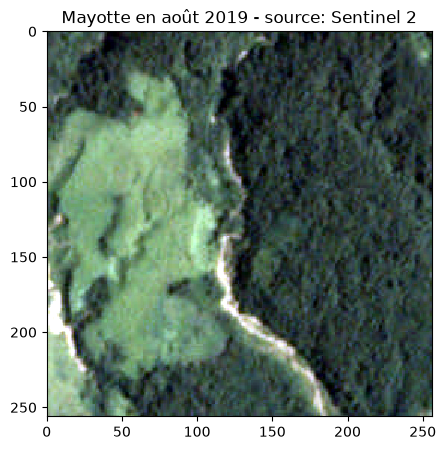

In [13]:
# Exemple
image = re.open("./images/clear/train_1.jpg")
image.info()

# Compositions colorées de Mayotte en 2019 et 2024
image.colorcomp(["1", "2", "3",], extent = "pixel", title = "Mayotte en août 2019 - source: Sentinel 2")

| | <center>Sentinel2_2019<center> | <center>Sentinel2_2024<center> |
|-|-|-|
| <center>**Date d'acquisition**<center> | <center>05/08/2019<center> | <center>23/08/2024<center> |
| <center>**Résolution spatiale**<center> | <center>10 mètres<center> | <center>10 mètres<center> |
| <center>**Bandes spectrales**<center> |<center>Coastal Aerosol / Blue / Green /<br>Red / Red Edge 1,2,3 / Near Infra-Red /<br>Narrow Near Infra-Red / Shortwave Infra-Red 1,2<center>|<center>Coastal Aerosol / Blue / Green /<br>Red / Red Edge 1,2,3 / Near Infra-Red /<br>Narrow Near Infra-Red / Shortwave Infra-Red 1,2<center>|
| <center>**Dimensions**<center> | <center>1447x1757 pixels<br>soit 14,47x17,57 km<center> | <center>1447x1757 pixels<br>soit 14,47x17,57 km<center> |

## <span style="color:orange">Création du jeu d'entraînement</span>
<span style="color:red">**A FAIRE : Créer le jeu d'entrainement en stackang toutes les images sans perdre l'information de la catégorie (catégorie qui dépend du dossier parent à l'origine). Du coup la catégorie, il faut la stocker dans un truc qui contient les labels des dossiers parents.  
Autre truc : c'est ici qu'il faut potentiellement ajouter des bandes par exemple de filtre gaussien et sobel (justifiés)si on veut aider nos modèles**
</span>

In [ ]:
# Une proposition de code pour les labels faite vite fais en cours
img_path = "./clouds/"
label = {}

for folder in os.listdir(img_path):
    for img in os.listdir(f"{img_path}{folder}"):
        label[img] = folder

with open("./label.txt", "w") as filout:
    for value in label:
        filout.write(value + "\t" + label[value] + "\n")

# <span style="color:red">**II - Modèles d'apprentissage supervisé**</span>
<span style="color:red">**A FAIRE : Créer des modèles simples (RF, KNN, SVM, NN (pas tous)) et moins simples (CNN) OU comparer un réseau de neuronne fromscrath et des réseaux pré entrainé (plus chiant).  
L'objectif c'est de tester deux ou trois modèles d'apprentissage supervisé en proposant pour chacun deux ou trois paramètrages différents  
Est-ce qu'on créer des boucles qui entrainent le modèle sur plusieurs paramètres où est-ce qu'on créer un bloc de code par paramètre ?**
</span>

## <span style="color:red">Random Forest</span>

### <span style="color:red">*Création et entraînement du modèle*</span>

In [ ]:
# Construction du modèle

In [ ]:
# Entrainement

### <span style="color:red">*Métriques d'évaluation de la qualité du modèle*</span>

In [14]:
# Penser à stocker les résultats pour une futur comparaison

## <span style="color:red">KNN</span>

### <span style="color:red">*Création et entraînement du modèle*</span>

### <span style="color:red">*Métriques d'évaluation de la qualité du modèle*</span>

## <span style="color:red">CNN</span>

### <span style="color:red">*Création et entraînement du modèle*</span>

### <span style="color:red">*Métriques d'évaluation de la qualité du modèle*</span>

# <span style="color:red">**III - Comparaison des modèles**</span>
<span style="color:red">**A FAIRE : Construire des tableaux et graphes pour discuter de nos résultats  
Quel modèle avec quel paramètre est le meilleur, sur quelle type d'image, lequel arrive un peu mieux gérer le haze, est-ce que les gros modèles sont vraiment plus puissant**
</span>